In [ ]:
# EDA_Toronto.py
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Carregamento dos dados
train = pd.read_csv("X_trainToronto.csv")
test = pd.read_csv("X_testToronto.csv")

# Visualização geral
print("Shape train:", train.shape)
print("Shape test:", test.shape)

Shape train: (17582, 13)
Shape test: (1324, 12)


In [ ]:
# soh para uma melhor visualização dos dados...
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=train)

https://docs.google.com/spreadsheets/d/1S-66RZ7S9wgVpRJWRrOJa_8TTAlbbLc_pnXucGz1sIA/edit#gid=0


In [ ]:
# ver os tipos de dados
train.info()

# Verificando valores nulos
print("\nValores nulos por coluna:\n", train.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17582 entries, 0 to 17581
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   business_id   17582 non-null  object 
 1   name          17582 non-null  object 
 2   address       17295 non-null  object 
 3   postal_code   17474 non-null  object 
 4   latitude      17582 non-null  float64
 5   longitude     17582 non-null  float64
 6   review_count  17582 non-null  int64  
 7   is_open       17582 non-null  int64  
 8   attributes    15014 non-null  object 
 9   categories    17555 non-null  object 
 10  hours         12905 non-null  object 
 11  loc           17582 non-null  object 
 12  destaque      17582 non-null  int64  
dtypes: float64(2), int64(3), object(8)
memory usage: 1.7+ MB

Valores nulos por coluna:
 business_id        0
name               0
address          287
postal_code      108
latitude           0
longitude          0
review_count       0
is_open  

In [ ]:
# Estatísticas descritivas
print("\nEstatísticas descritivas:\n", train.describe())


Estatísticas descritivas:
            latitude     longitude  review_count       is_open      destaque
count  17582.000000  17582.000000  17582.000000  17582.000000  17582.000000
mean      43.678576    -79.395067     27.150267      0.758105      0.060061
std        0.043121      0.059692     60.350968      0.428243      0.237607
min       43.560365    -79.713930      3.000000      0.000000      0.000000
25%       43.650481    -79.418845      4.000000      1.000000      0.000000
50%       43.664172    -79.394105      9.000000      1.000000      0.000000
75%       43.688730    -79.375790     24.000000      1.000000      0.000000
max       43.881942    -79.019777   2121.000000      1.000000      1.000000


In [ ]:
# Verificar cardinalidade de variáveis categóricas
cat_cols = train.select_dtypes(include='object').columns
for col in cat_cols:
    print(f"\n{col} - {train[col].nunique()} categorias")
    print(train[col].value_counts(normalize=True).head())


business_id - 17582 categorias
business_id
syksx_OMlfHmVmurGTZU5w    0.000057
vHzWmPWHN4J1hRR3W3AMQg    0.000057
15to24Q-otAHmto7FzsWRg    0.000057
8aqKdf4G4AAir8k_Kdslvg    0.000057
uxU1vr5AhhkTQ83X0bpeyg    0.000057
Name: proportion, dtype: float64

name - 14775 categorias
name
Starbucks             0.008418
Tim Hortons           0.004834
Shoppers Drug Mart    0.003185
Subway                0.002616
McDonald's            0.002389
Name: proportion, dtype: float64

address - 13974 categorias
address
3401 Dufferin Street    0.002313
220 Yonge Street        0.002255
25 The West Mall        0.001214
2300 Yonge Street       0.001041
218 Yonge Street        0.000983
Name: proportion, dtype: float64

postal_code - 5210 categorias
postal_code
M5B 2H1    0.005151
M6A 2T9    0.003548
M5V        0.003434
M5T        0.003148
M4K 1N2    0.002919
Name: proportion, dtype: float64

attributes - 11141 categorias
attributes
{'ByAppointmentOnly': 'True'}                                                 

#-Resumo
###14.775 nomes diferentes
###13.974 endereços únicos
###5.210 códigos postais
###attributes – 11.141 combinações
####Alguns padrões se repetem, como:

*  ByAppointmentOnly: True
*  GoodForKids: True
#### Com tratamento adequado (extração de chaves individuais), pode fornecer informações úteiis...

###Conclusões
####Muitas colunas têm alta cardinalidade (muitos valores únicos), o que indica que:


*   Algumas podem ser descartadas
*   Outras precisam ser tratadas com cuidado



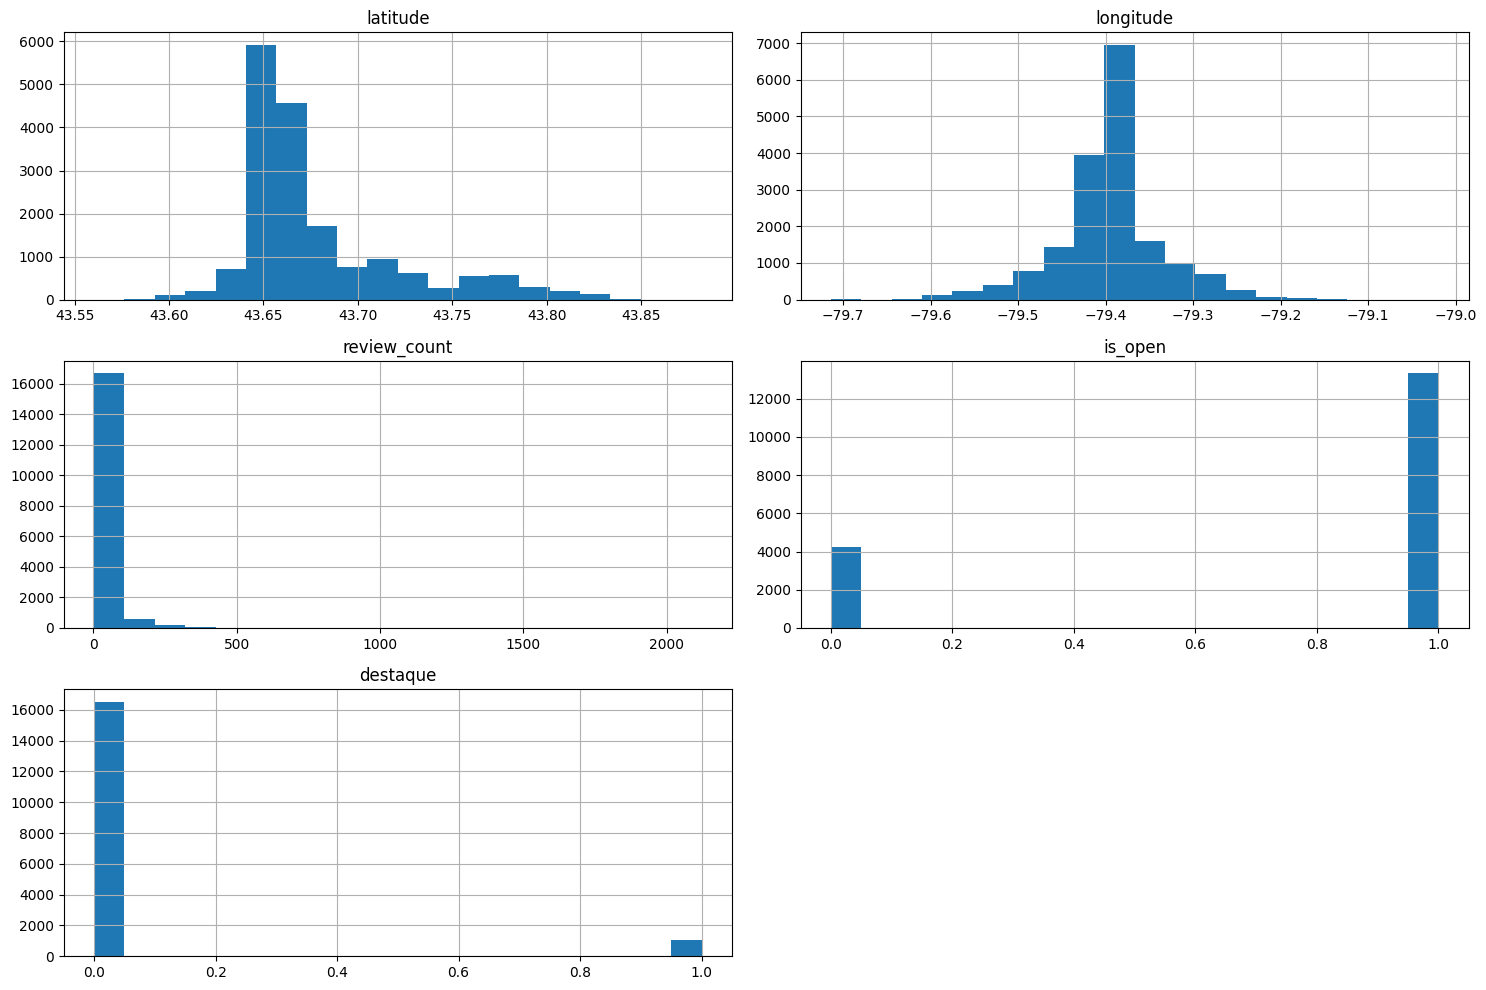

In [ ]:
# Distribuições das features numéricas
num_cols = train.select_dtypes(include='number').columns
train[num_cols].hist(bins=20, figsize=(15, 10))
plt.tight_layout()
plt.show()


1. latitude


*  Distribuição levemente assimétrica à direita.
*   A maioria dos estabelecimentos está entre as latitudes 43.64 e 43.68, o que faz sentido considerando a cidade de Toronto.

* --> Pode indicar uma concentração de negócios em uma região central da cidade???



2. longitude
* Distribuição com um pico claro em torno de -79.4.
* Simétrica e bem centrada — também reflete concentração geográfica.
* --> Latitude e longitude podem ser usados para criar clusters de localização ou calcular distância a pontos de interesse.

3. review_count
* Distribuição extremamente assimétrica (direita).
* A maioria absoluta dos estabelecimentos tem poucas reviews (menos de 100).
* Alguns estabelecimentos têm contagens de avaliação bem altas (>2000).

* --> Pode-se usar uma transformação logarítmica para normalizar.

* --> Outliers podem ser relevantes (estabelecimentos muito populares).

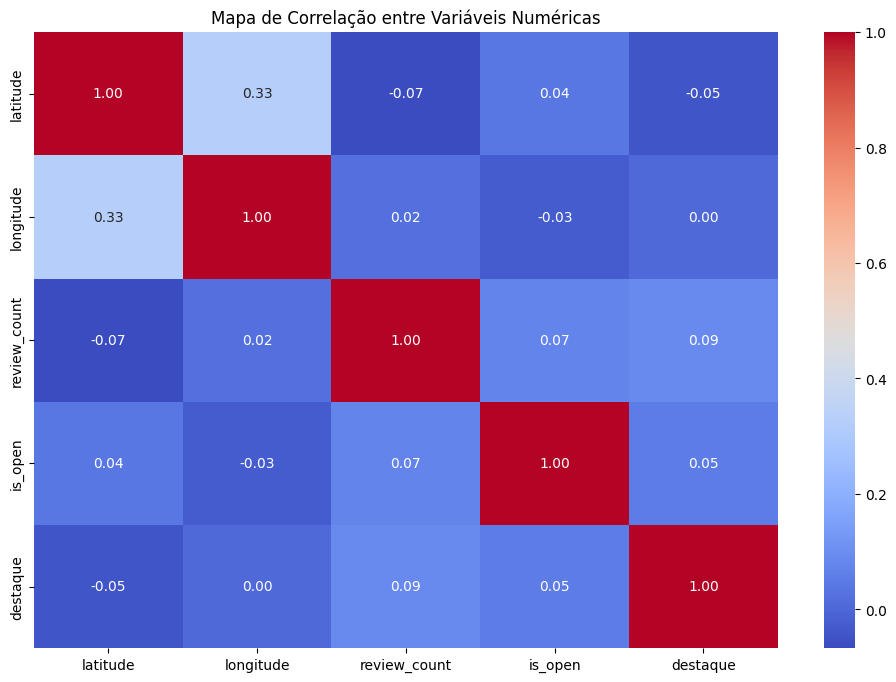

In [ ]:
# Correlação
plt.figure(figsize=(12, 8))
sns.heatmap(train[num_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Mapa de Correlação entre Variáveis Numéricas")
plt.show()

* latitude e longitude: correlação de 0.33 — indica uma leve relação (possivelmente geográfica).

* review_count tem baixa correlação com todas as outras — ou seja, número de avaliações não depende diretamente das outras variáveis.

* is_open e destaque têm correlação fraca (0.05).

* Todas as outras correlações estão próximas de zero, indicando que suas variáveis numéricas são pouco redundantes entre si.